# Water Emissions Analysis Over Years
**Country:** Denmark  
**Period:** 2008–2024  
**Data Source:** EEA Waterbase – Emissions, 2026

## Project Overview
This project analyzes water emissions in Denmark from 2008 to 2024 using the EEA Waterbase – Emissions dataset.

The analysis includes data loading, cleaning, unit conversion, yearly emissions calculations, and visualization of emission trends across different pollutants.

## Notebook Workflow
1. Import required Python libraries.
2. Load the original dataset using a direct download link.
3. Filter the data for Denmark and the selected period.
4. Clean and prepare the data for analysis.
5. Calculate yearly emissions and pollutant totals.
6. Create visualizations to identify emission patterns.
7. Summarize the key findings.


The created graphs illustrate water emissions in Denmark from 2008 to 2024. They present annual total emissions, emissions by pollutant, and changes in pollutant contributions over time.

**Key Findings:**

1.The highest recorded annual emissions were observed in 2017, reaching approximately 82.68 million kg/a.

2.The lowest recorded annual emissions occurred in 2008, at approximately 1.14 million kg/a.

3.Emissions increased substantially between 2008 and 2017, although fluctuations were observed during this period.

4.Following the peak in 2017, emissions decreased significantly in 2018 and subsequently showed variations in the following years.

5.Emissions increased from approximately 19.56 million kg/a in 2020 to 56.55 million kg/a in 2024.

**Tools:** Python, Google Colab, Pandas, Matplotlib, Seaborn.

In [29]:
import pandas as pd
import os

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
# In this file, we are going to export the file.
# extracting the Denmark data based on country code = "DK"
# deleting unnecessary columns

file_path = "https://drive.google.com/uc?export=download&id=17THboaZXMUXM0HADEP_UJe3AaJ8Ak3fE"
waterbase_data = pd.read_csv(file_path)

denmark_data = waterbase_data[waterbase_data["countryCode"]=="DK"]

#dropping the unnecessary columns
denmark_data = denmark_data.drop(columns=["spatialUnitIdentifierScheme","parameterEPRTRfacilities","observedPropertyDeterminandCode",
                                          "metadata_beginLifeSpanVersion", "spatialUnitIdentifier", "Remarks", "metadata_versionId",
                                          "metadata_observationStatus", "metadata_statements", "UID"])
denmark_data.info()



<class 'pandas.core.frame.DataFrame'>
Index: 926 entries, 1788 to 158180
Data columns (total 9 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   countryCode                       926 non-null    object 
 1   phenomenonTimeReferencePeriod     926 non-null    object 
 2   observedPropertyDeterminandLabel  926 non-null    object 
 3   parameterEmissionsSourceCategory  926 non-null    object 
 4   resultEmissionsValue              885 non-null    float64
 5   resultEmissionsUom                926 non-null    object 
 6   procedureEmissionsMethod          862 non-null    object 
 7   resultObservationStatus           418 non-null    object 
 8   metadata_statusCode               926 non-null    object 
dtypes: float64(1), object(8)
memory usage: 72.3+ KB


/tmp/ipykernel_412/1230189300.py:2: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  waterbase_data = pd.read_csv(file_path)


In [4]:
# Here We are finding the null & empty values in entire denmark data.


# to check total count of null values in entire table by each column
nullCount = denmark_data.isnull().sum()
# this is to check empty values, result is 0. so, there are no empty values
(denmark_data == '').sum()

print(nullCount)


countryCode                           0
phenomenonTimeReferencePeriod         0
observedPropertyDeterminandLabel      0
parameterEmissionsSourceCategory      0
resultEmissionsValue                 41
resultEmissionsUom                    0
procedureEmissionsMethod             64
resultObservationStatus             508
metadata_statusCode                   0
dtype: int64


In [5]:
#In this note, we are replacing empty, null values with relevant values
#data cleaning

# replace 44 null rows for resultEmissionsValue with 0
denmark_data['resultEmissionsValue'] = denmark_data['resultEmissionsValue'].fillna(0.000)
#Check the rows which are null for resultEmissionsValue, it is 0
denmark_data[denmark_data['resultEmissionsValue'].isnull()]

# replace 64 null rows for procedureEmissionsMethod with 'not specified'
denmark_data['procedureEmissionsMethod'] = denmark_data['procedureEmissionsMethod'].fillna('not specified')
#denmark_data[denmark_data['resultEmissionsValue'].isnull()]
# check the count of "procedureEmissionsMethod" values
denmark_data['procedureEmissionsMethod'].value_counts(dropna=False)

#replace 508 resultObservationStatus with NS
denmark_data['resultObservationStatus'] = denmark_data['resultObservationStatus'].fillna('NS')
denmark_data['resultObservationStatus'].value_counts(dropna=False)





,count
resultObservationStatus,
NS,508
A,242
X,128
N,22
O,21
M,5


In [6]:
# Here we are finiding and removing duplicate rows with 0 emission values

display(denmark_data.duplicated().sum())


duplicates = denmark_data[denmark_data.duplicated(keep=False)]

duplicates[duplicates['resultObservationStatus'] == "NS"].count()

#remove rows from duplicates having 'not specified, 0's and NS'

denmark_data = denmark_data.drop(
duplicates[duplicates['resultObservationStatus'] == 'NS'].index)

print(len(duplicates[duplicates['resultObservationStatus'] == 'NS']))
(duplicates['resultObservationStatus'] == 'NS').sum()


np.int64(33)

2


np.int64(2)

In [7]:
# create new csv of cleaned denmark datat to use it further.

# resetting the index after removing few rows.
denmark_data = denmark_data.reset_index(drop=True)

#save new cleaned file, index is false because in above code we reset the index
denmark_data.to_csv('denmark_cleaned_working.csv', index=False)

In [8]:
#using the cleaned denmark data for further actions

from google.colab import drive
import pandas as pd

# Mount Google Drive
#drive.mount('/content/drive')
file_path= '/content/denmark_cleaned_working.csv'
water_emissiona_dk = pd.read_csv(file_path)
water_emissiona_dk.columns.tolist()

['countryCode',
 'phenomenonTimeReferencePeriod',
 'observedPropertyDeterminandLabel',
 'parameterEmissionsSourceCategory',
 'resultEmissionsValue',
 'resultEmissionsUom',
 'procedureEmissionsMethod',
 'resultObservationStatus',
 'metadata_statusCode']

In [9]:
#here we are checking the values/measurements are using same units or not
#we have found 2 differnt units -  "t/a & kg/a" (tonnes & kg per annum)

water_emissiona_dk['originalEmissionValue'] = water_emissiona_dk['resultEmissionsValue']

denmark_data['resultEmissionsUom'].value_counts()
water_emissiona_dk['resultEmissionsValue'].isnull().sum()
water_emissiona_dk['resultEmissionsUom'].value_counts()



,count
resultEmissionsUom,
t/a,531
kg/a,393


In [10]:
#run only once

#The dataset reports emissions using two measurement units:
#tonnes per annum (t/a) and kilograms per annum (kg/a). For consistency,
#all emission values were converted to kg/a before analysis.

water_emissiona_dk.loc[
    water_emissiona_dk['resultEmissionsUom'] == 't/a',
    'resultEmissionsValue'
] *= 1000
water_emissiona_dk.loc[
    water_emissiona_dk['resultEmissionsUom'] == 't/a',
    'resultEmissionsUom'
] = 'kg/a'



In [32]:
#checking the conversion is correct or not by getting top 10 values
water_emissiona_dk[
    water_emissiona_dk['originalEmissionValue'] != water_emissiona_dk['resultEmissionsValue']
][['originalEmissionValue', 'resultEmissionsValue', 'resultEmissionsUom']].head()

water_emissiona_dk['resultEmissionsUom'].value_counts()
(water_emissiona_dk['resultEmissionsValue'] == 0).sum()


np.int64(111)

In [12]:
#creating new csv after all the data cleaned
#and converting units from t/a to kg/a.

water_emissiona_dk.to_csv('denmark_water_emissions_final.csv', index=False)
water_emission_final = pd.read_csv(file_path)
emissions_by_year = water_emission_final.groupby(
   ['phenomenonTimeReferencePeriod', 'observedPropertyDeterminandLabel']
)['resultEmissionsValue'].sum().reset_index()



Highest emissions:
phenomenonTimeReferencePeriod        2017.0
resultEmissionsValue             82676637.2
Name: 8, dtype: float64

Lowest emissions:
phenomenonTimeReferencePeriod       2008.0
resultEmissionsValue             1139480.0
Name: 0, dtype: float64


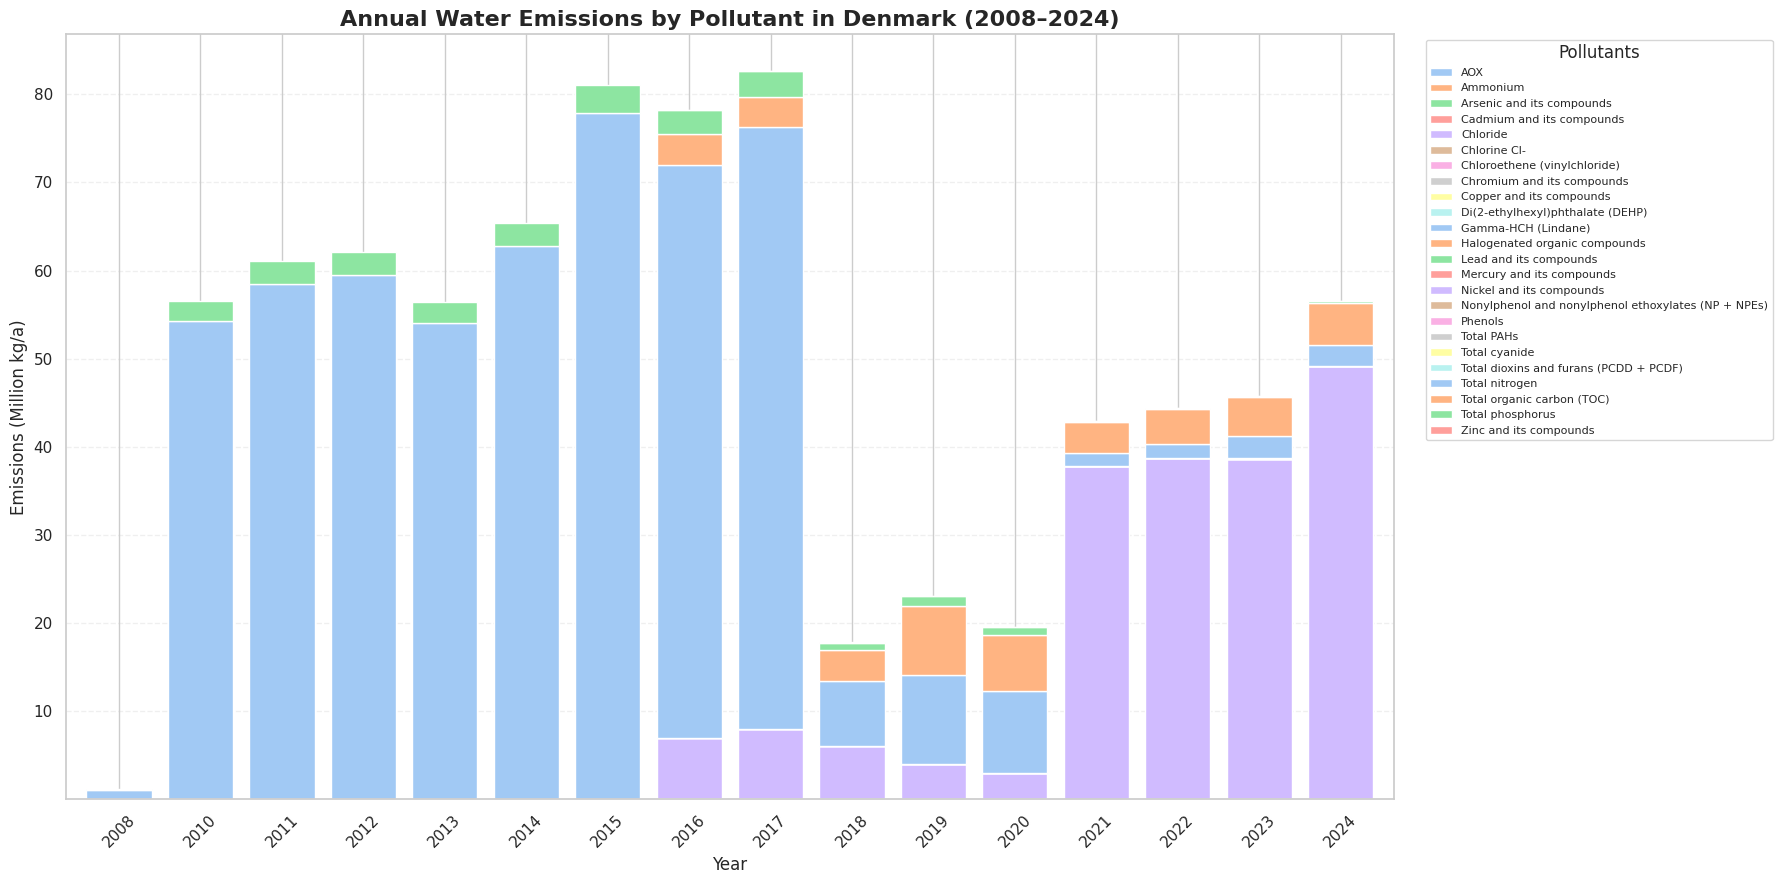

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create pivot table
emissions_pivot = emissions_by_year.pivot_table(
    index='phenomenonTimeReferencePeriod',
    columns='observedPropertyDeterminandLabel',
    values='resultEmissionsValue',
    aggfunc='sum'
)

# Convert emissions to million kg/a
emissions_pivot = emissions_pivot / 1_000_000

# Shorten the long PAHs pollutant name
short_names = {
    'Total PAHs (Benzo(a)pyrene, Benzo(b)fluoranthene, Benzo(k)fluoranthene, Benzo(ghi)perylene, Indeno(1,2,3-cd)pyrene)': 'Total PAHs'
}

emissions_pivot = emissions_pivot.rename(columns=short_names)

# Generate light pastel colors for each pollutant
number_of_pollutants = len(emissions_pivot.columns)

colors = sns.color_palette(
    palette="pastel",
    n_colors=number_of_pollutants
)

# Plot stacked bars
ax = emissions_pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(18, 9),
    color=colors,
    width=0.8
)

plt.title(
    'Annual Water Emissions by Pollutant in Denmark (2008–2024)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Year')
plt.ylabel('Emissions (Million kg/a)')

plt.xticks(rotation=45)

plt.legend(
    title='Pollutants',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=8
)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

plt.show()

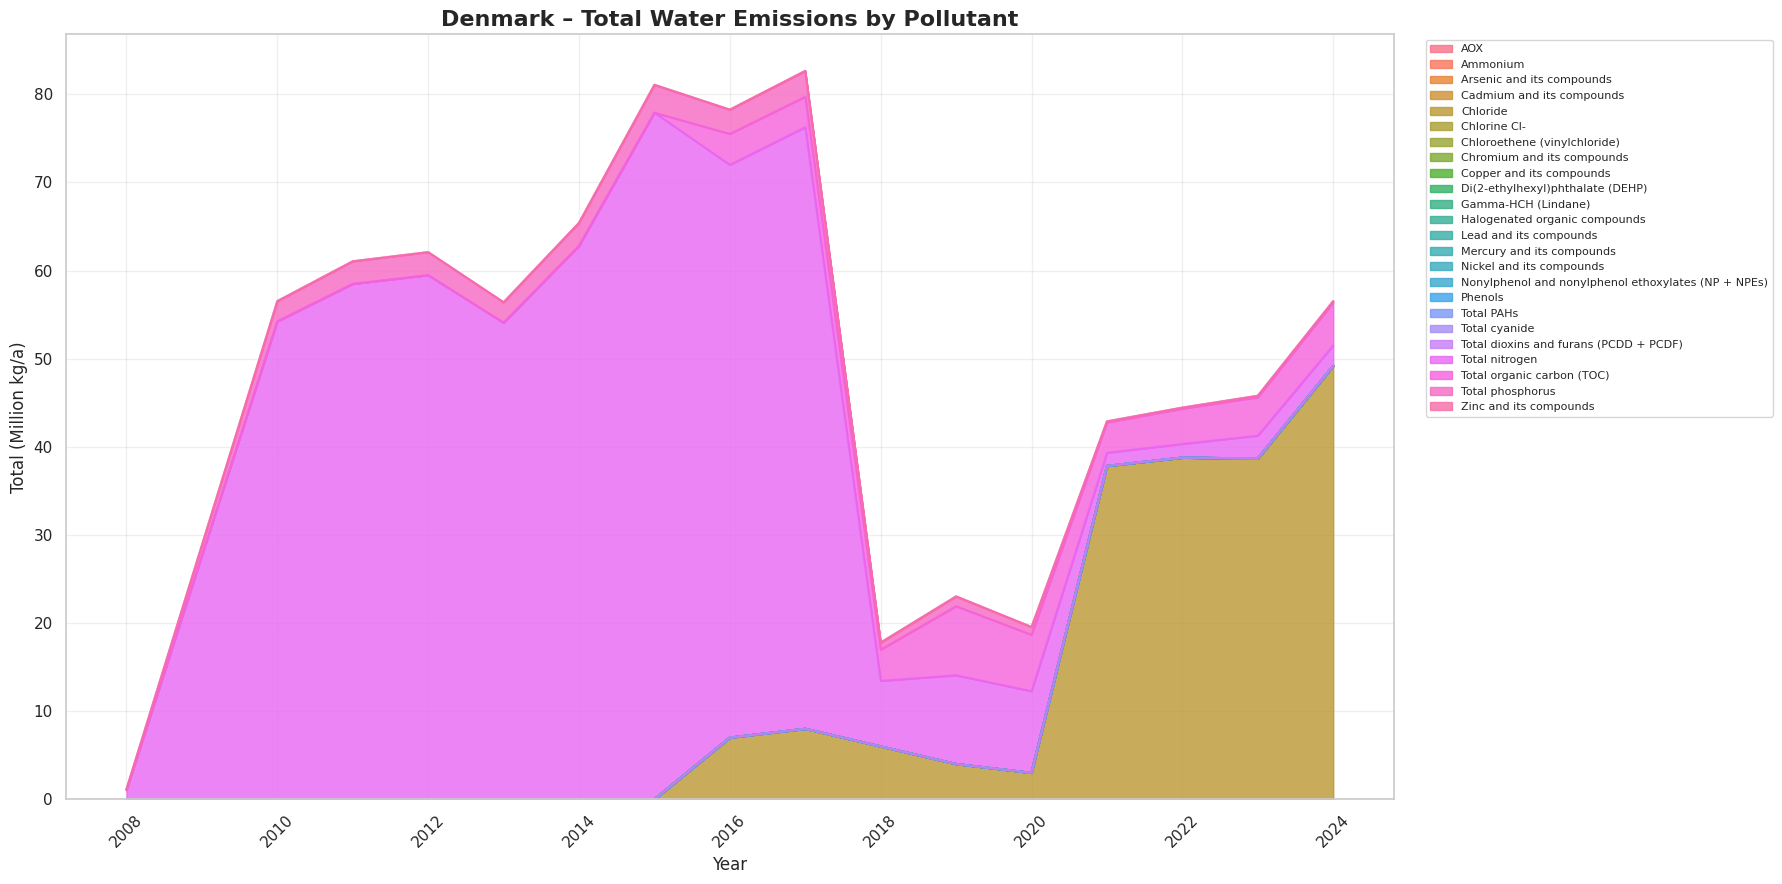

In [47]:
emissions_pivot = emissions_by_year.pivot_table(
    index='phenomenonTimeReferencePeriod',
    columns='observedPropertyDeterminandLabel',
    values='resultEmissionsValue',
    aggfunc='sum',
    fill_value=0
)

#emissions_pivot = emissions_pivot.sort_index()

# Convert emissions from kg/a to million kg/a
short_names = {
    'Total PAHs (Benzo(a)pyrene, Benzo(b)fluoranthene, Benzo(k)fluoranthene, Benzo(ghi)perylene, Indeno(1,2,3-cd)pyrene)': 'Total PAHs'
}
emissions_pivot = emissions_pivot.rename(columns=short_names)
emissions_pivot = emissions_pivot / 1_000_000

fig, ax = plt.subplots(figsize=(18, 9))

colors = sns.color_palette(
    "husl", emissions_pivot.shape[1]
)

emissions_pivot.plot.area(
    stacked=True,
    ax=ax,
    color=colors,
    alpha=0.8
)

ax.set_title(
    'Denmark – Total Water Emissions by Pollutant',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Total (Million kg/a)', fontsize=12)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=8
)

ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# Calculate total emissions per year

yearly_emissions = (
    emissions_by_year
    .groupby('phenomenonTimeReferencePeriod')
    ['resultEmissionsValue']
    .sum()
    .reset_index()
)

# Sort by year
yearly_emissions = yearly_emissions.sort_values(
    'phenomenonTimeReferencePeriod'
)

# Display the results
print(yearly_emissions)

print("Number of pollutants:",
      emissions_pivot.shape[1])

print("Pollutant names:")
print(emissions_pivot.columns.tolist())

# Year with highest emissions
highest = yearly_emissions.loc[
    yearly_emissions['resultEmissionsValue'].idxmax()
]

# Year with lowest emissions
lowest = yearly_emissions.loc[
    yearly_emissions['resultEmissionsValue'].idxmin()
]

print("Highest emissions:")
print(highest)

print("\nLowest emissions:")
print(lowest)

    phenomenonTimeReferencePeriod  resultEmissionsValue
0                            2008          1.139480e+06
1                            2010          5.653640e+07
2                            2011          6.105740e+07
3                            2012          6.209700e+07
4                            2013          5.640500e+07
5                            2014          6.542400e+07
6                            2015          8.108300e+07
7                            2016          7.826708e+07
8                            2017          8.267664e+07
9                            2018          1.780228e+07
10                           2019          2.303708e+07
11                           2020          1.955735e+07
12                           2021          4.289567e+07
13                           2022          4.445992e+07
14                           2023          4.580289e+07
15                           2024          5.654734e+07
Number of pollutants: 24
Pollutant names:
['AOX'

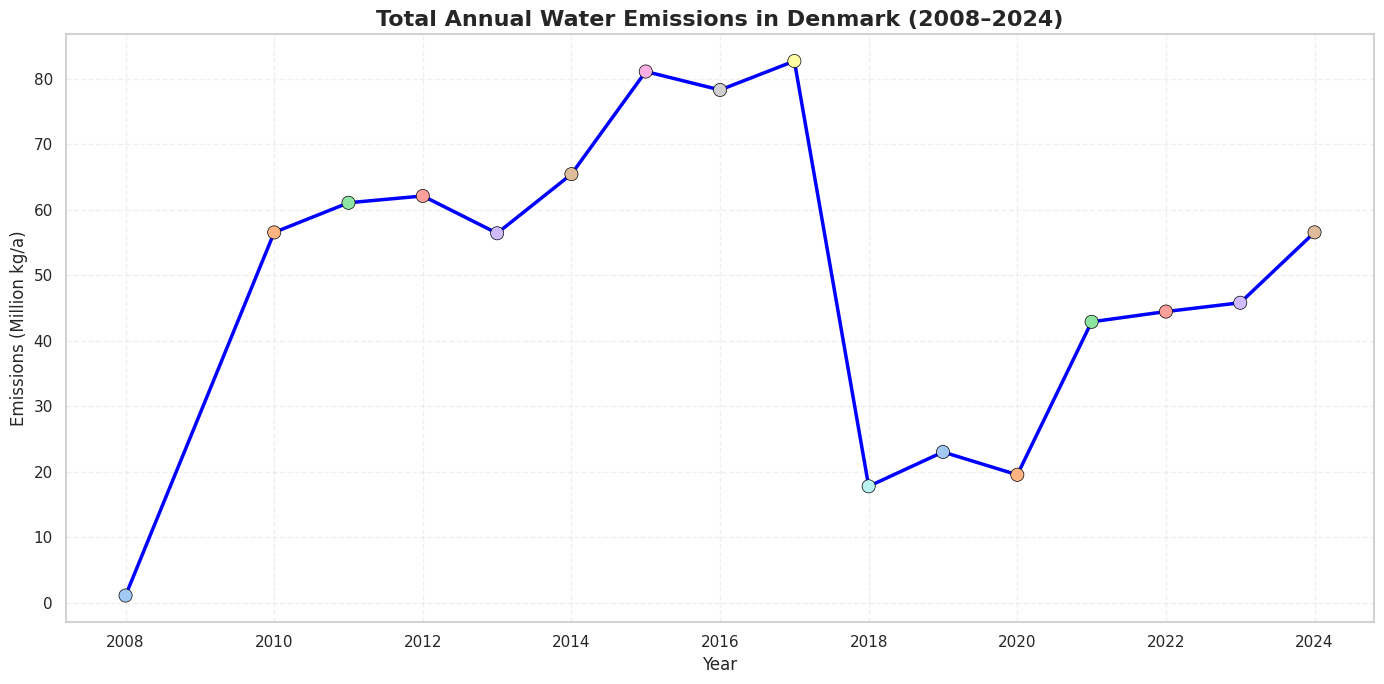

In [35]:
fig, ax = plt.subplots(figsize=(14, 7))

# Blue line connecting all points
ax.plot(
    yearly_emissions['phenomenonTimeReferencePeriod'],
    yearly_emissions['Emissions_Million_kg'],
    color='blue',
    linewidth=2.5,
    zorder=1
)

# Different color for each dot
colors = sns.color_palette("pastel", len(yearly_emissions))

ax.scatter(
    yearly_emissions['phenomenonTimeReferencePeriod'],
    yearly_emissions['Emissions_Million_kg'],
    color=colors,
    s=90,
    edgecolors='black',
    linewidths=0.5,
    zorder=2
)

ax.set_title(
    'Total Annual Water Emissions in Denmark (2008–2024)',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Emissions (Million kg/a)', fontsize=12)

ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()